# Convergence study: CRR binomial tree vs Black-Scholes

Prices the same European call with every number of steps from N = 10 to N = 400 and compares each price to the exact Black-Scholes value.

Example option: S0 = 75, K = 65, T = 1 year, r = 5%, σ = 30%.

In [1]:
import math
import time
import matplotlib.pyplot as plt

from binomial_tree import fun, black_scholes

SO, K, T, r, sigma = 75.0, 65.0, 1, 0.05, 0.30
bs_price = black_scholes(SO, K, T, r, sigma, "call")
print(f"Black-Scholes call price: {bs_price:.4f}")

Black-Scholes call price: 16.3579


In [2]:
# Price the call with every N from 10 to 400 steps
Ns = list(range(10, 401))
start = time.time()
prices = [fun(SO, K, T, r, N, sigma, "call") for N in Ns]
errors = [price - bs_price for price in prices]
print(f"Priced {len(Ns)} trees in {time.time() - start:.1f} seconds\n")

for N in [10, 11, 50, 51, 100, 101, 200, 201, 400]:
    i = Ns.index(N)
    print(f"N = {N:3d}   tree = {prices[i]:.4f}   error = {errors[i]:+.4f}")

Priced 391 trees in 8.5 seconds

N =  10   tree = 16.4447   error = +0.0868
N =  11   tree = 16.4342   error = +0.0763
N =  50   tree = 16.3810   error = +0.0231
N =  51   tree = 16.3641   error = +0.0062
N = 100   tree = 16.3713   error = +0.0134
N = 101   tree = 16.3532   error = -0.0048
N = 200   tree = 16.3645   error = +0.0065
N = 201   tree = 16.3563   error = -0.0016
N = 400   tree = 16.3594   error = +0.0015


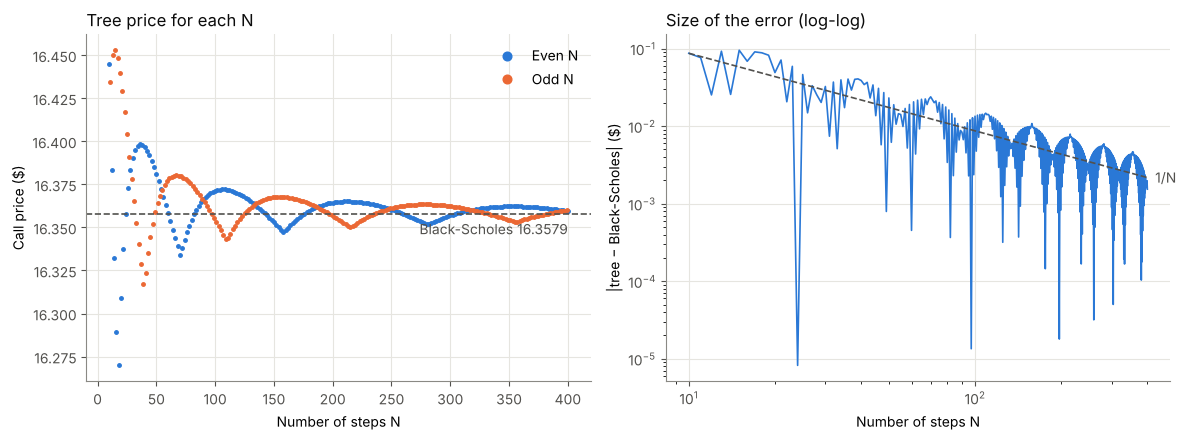

In [3]:
BLUE, ORANGE, GRAY, INK, MUTED = "#2a78d6", "#eb6834", "#52514e", "#0b0b0b", "#8a8984"
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))

# Left: price vs N, with the Black-Scholes price as a reference line
even = [i for i, N in enumerate(Ns) if N % 2 == 0]
odd = [i for i, N in enumerate(Ns) if N % 2 == 1]
ax1.plot([Ns[i] for i in even], [prices[i] for i in even], "o", color=BLUE, markersize=2.5, label="Even N")
ax1.plot([Ns[i] for i in odd], [prices[i] for i in odd], "o", color=ORANGE, markersize=2.5, label="Odd N")
ax1.axhline(bs_price, color=GRAY, linestyle="--", linewidth=1.2)
ax1.text(400, bs_price - 0.004, f"Black-Scholes {bs_price:.4f}", color=GRAY, va="top", ha="right")
ax1.legend(frameon=False, loc="upper right", markerscale=2.5)
ax1.set_title("Tree price for each N", loc="left", color=INK)
ax1.set_xlabel("Number of steps N")
ax1.set_ylabel("Call price ($)")

# Right: size of the error on log-log axes, with a 1/N reference line
abs_err = [abs(e) for e in errors]
ax2.loglog(Ns, abs_err, color=BLUE, linewidth=1.2)
ref = [abs_err[0] * Ns[0] / N for N in Ns]          # a line falling like 1/N
ax2.loglog(Ns, ref, color=GRAY, linestyle="--", linewidth=1.2)
ax2.text(Ns[-1], ref[-1], "  1/N", color=GRAY, va="center")
ax2.set_title("Size of the error (log-log)", loc="left", color=INK)
ax2.set_xlabel("Number of steps N")
ax2.set_ylabel("|tree − Black-Scholes| ($)")

for ax in (ax1, ax2):
    ax.grid(True, color="#e6e5e0", linewidth=0.8)
    ax.set_axisbelow(True)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_color(MUTED)
    ax.tick_params(colors=GRAY)

plt.tight_layout()
plt.savefig("images/convergence.png", dpi=150)
plt.show()

## What the plots show

1. **The error shrinks like 1/N.** On the log-log plot the error follows the dashed 1/N line: ten times the steps gives about a tenth of the error (first-order convergence).
2. **It zig-zags.** Even and odd N trace two separate waves, so adding a step can make the price worse. N = 51 is closer to Black-Scholes than N = 100.

## Why it zig-zags

The call payoff max(S − K, 0) has a kink at the strike. At expiry the tree has only N + 1 possible prices, so the error depends on where the strike falls between the two nearest final nodes (0 or 1 = on a node, 0.5 = halfway). Adding one step shifts that position by about half a gap, because even N always has a node at S0 and odd N never does. The cell below measures it.

In [4]:
def strike_position(N):
    """Where K sits between the two nearest final nodes: 0 or 1 = on a node, 0.5 = halfway."""
    dt = T / N
    j = (math.log(K / SO) / (sigma * math.sqrt(dt)) + N) / 2   # (fractional) number of up-moves that lands on K
    return j - math.floor(j)

print(" N   even/odd   strike position   error")
for N in [69, 70, 71, 109, 110, 111]:
    err = fun(SO, K, T, r, N, sigma, "call") - bs_price
    print(f"{N:3d}   {'even' if N % 2 == 0 else 'odd ':4s}       {strike_position(N):.2f}          {err:+.4f}")

 N   even/odd   strike position   error
 69   odd        0.52          +0.0222
 70   even       0.00          -0.0238
 71   odd        0.49          +0.0218
109   odd        0.01          -0.0146
110   even       0.50          +0.0140
111   odd        0.99          -0.0142


With a node right on the strike the tree prices too low; with the strike halfway between nodes it prices too high. Neighbouring N sit at opposite positions, which is the zig-zag.